In [1]:
!pip -q install spacy pandas matplotlib

In [2]:
import spacy
import pandas as pd
import matplotlib.pyplot as plt
from spacy import displacy

print("spaCy version:", spacy.__version__)

spaCy version: 3.8.16


In [3]:
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 62.7 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [4]:
import spacy

nlp = spacy.load("en_core_web_sm")

print("Model loaded successfully!")
print("Pipeline components:", nlp.pipe_names)

Model loaded successfully!
Pipeline components: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


In [5]:
text = """
Microsoft CEO Satya Nadella visited London on Monday
to discuss artificial intelligence with UK officials.
"""

doc = nlp(text)

for ent in doc.ents:
    print(ent.text, "->", ent.label_)

Microsoft -> ORG
Satya Nadella -> PERSON
London -> GPE
Monday -> DATE
UK -> GPE


In [6]:
from spacy import displacy

displacy.render(doc, style="ent", jupyter=True)

In [7]:
!pip install -q "datasets==3.6.0"

In [8]:
#!pip install -U datasets huggingface_hub

In [9]:
from datasets import load_dataset

dataset = load_dataset("eriktks/conll2003")

print(dataset)
print("Training examples:", len(dataset["train"]))
print("Validation examples:", len(dataset["validation"]))
print("Test examples:", len(dataset["test"]))

The repository for eriktks/conll2003 contains custom code which must be executed to correctly load the dataset. You can inspect the repository content at https://hf.co/datasets/eriktks/conll2003.
You can avoid this prompt in future by passing the argument `trust_remote_code=True`.

Do you wish to run the custom code? [y/N] y


Generating train split:   0%|          | 0/14041 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3250 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3453 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})
Training examples: 14041
Validation examples: 3250
Test examples: 3453


In [10]:
example = dataset["train"][0]

print("Tokens:")
print(example["tokens"])

print("\nNER tag IDs:")
print(example["ner_tags"])

ner_features = dataset["train"].features["ner_tags"].feature
print("\nNER tag names:")
print(ner_features.names)

Tokens:
['EU', 'rejects', 'German', 'call', 'to', 'boycott', 'British', 'lamb', '.']

NER tag IDs:
[3, 0, 7, 0, 0, 0, 7, 0, 0]

NER tag names:
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']


In [11]:
def extract_entities(text):
    doc = nlp(text)

    entities = []

    for ent in doc.ents:
        if ent.label_ in ["PERSON", "ORG", "GPE", "LOC"]:
            entities.append({
                "Entity": ent.text,
                "Category": ent.label_
            })

    return entities


news_text = """
Microsoft CEO Satya Nadella visited London to meet
officials from the United Kingdom. He later travelled
to Paris to discuss technology with Google executives.
"""

entities = extract_entities(news_text)

entities_df = pd.DataFrame(entities)
display(entities_df)

,Entity,Category
0,Microsoft,ORG
1,Satya Nadella,PERSON
2,London,GPE
3,the United Kingdom,GPE
4,Paris,GPE
5,Google,ORG


In [12]:
doc = nlp(news_text)

displacy.render(
    doc,
    style="ent",
    jupyter=True
)

In [13]:
from spacy.pipeline import EntityRuler

# Create a separate spaCy pipeline for rule-based NER
rule_nlp = spacy.blank("en")

# Add the rule-based entity recognizer
ruler = rule_nlp.add_pipe("entity_ruler")

# Define entity patterns
patterns = [
    {"label": "PERSON", "pattern": "Satya Nadella"},
    {"label": "ORG", "pattern": "Microsoft"},
    {"label": "ORG", "pattern": "Google"},
    {"label": "GPE", "pattern": "London"},
    {"label": "GPE", "pattern": "United Kingdom"},
    {"label": "GPE", "pattern": "Paris"},
]

ruler.add_patterns(patterns)

# Test the rule-based system
news_text = """
Microsoft CEO Satya Nadella visited London to meet
officials from the United Kingdom. He later travelled
to Paris to discuss technology with Google executives.
"""

rule_doc = rule_nlp(news_text)

rule_results = pd.DataFrame([
    {
        "Entity": ent.text,
        "Category": ent.label_
    }
    for ent in rule_doc.ents
])

display(rule_results)

,Entity,Category
0,Microsoft,ORG
1,Satya Nadella,PERSON
2,London,GPE
3,United Kingdom,GPE
4,Paris,GPE
5,Google,ORG


In [14]:
model_doc = nlp(news_text)

model_results = pd.DataFrame([
    {
        "Entity": ent.text,
        "Category": ent.label_
    }
    for ent in model_doc.ents
    if ent.label_ in ["PERSON", "ORG", "GPE", "LOC"]
])

print("RULE-BASED NER")
display(rule_results)

print("MODEL-BASED NER")
display(model_results)

RULE-BASED NER


,Entity,Category
0,Microsoft,ORG
1,Satya Nadella,PERSON
2,London,GPE
3,United Kingdom,GPE
4,Paris,GPE
5,Google,ORG


MODEL-BASED NER


,Entity,Category
0,Microsoft,ORG
1,Satya Nadella,PERSON
2,London,GPE
3,the United Kingdom,GPE
4,Paris,GPE
5,Google,ORG


,Entity,Category,Count
0,Microsoft,ORG,2
1,London,GPE,2
2,Google,ORG,2
3,Tim Cook,PERSON,2
4,Satya Nadella,PERSON,1
5,UK,GPE,1
6,Paris,GPE,1
7,Apple,ORG,1
8,the United States,GPE,1


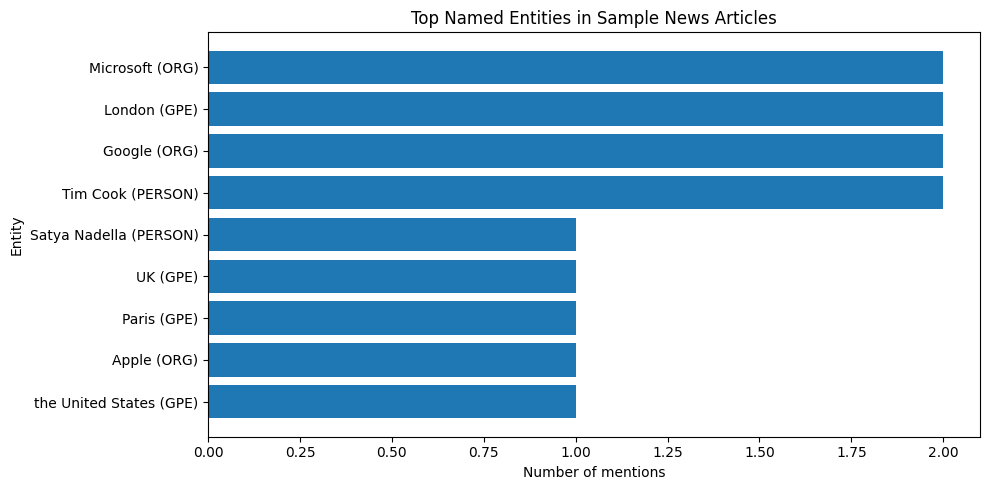

In [15]:
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

news_articles = [
    "Microsoft CEO Satya Nadella visited London to meet UK officials.",
    "Google opened a new office in Paris, according to company executives.",
    "Apple CEO Tim Cook travelled to London to discuss technology.",
    "Microsoft and Google compete in the technology industry.",
    "Tim Cook met officials in the United States."
]

entity_counts = Counter()

for article in news_articles:
    doc = nlp(article)

    for ent in doc.ents:
        if ent.label_ in ["PERSON", "ORG", "GPE", "LOC"]:
            entity_counts[(ent.text, ent.label_)] += 1

entity_df = pd.DataFrame(
    [
        {
            "Entity": entity,
            "Category": category,
            "Count": count
        }
        for (entity, category), count in entity_counts.items()
    ]
)

entity_df = entity_df.sort_values(
    "Count", ascending=False
).reset_index(drop=True)

display(entity_df)

# Plot the most frequently detected entities
top_entities = entity_df.head(10).copy()

if not top_entities.empty:
    top_entities["Display"] = (
        top_entities["Entity"] + " (" +
        top_entities["Category"] + ")"
    )

    plt.figure(figsize=(10, 5))
    plt.barh(top_entities["Display"], top_entities["Count"])
    plt.xlabel("Number of mentions")
    plt.ylabel("Entity")
    plt.title("Top Named Entities in Sample News Articles")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print("No entities were detected.")

In [16]:
# Select 5 real examples from the CoNLL-2003 test split
test_examples = dataset["test"].select(range(5))

for i, example in enumerate(test_examples):
    # Reconstruct the article text from its tokens
    article = " ".join(example["tokens"])

    # Run model-based NER
    doc = nlp(article)

    print(f"\n{'=' * 60}")
    print(f"ARTICLE {i + 1}")
    print(article[:500])

    print("\nSPACY ENTITIES:")
    for ent in doc.ents:
        if ent.label_ in ["PERSON", "ORG", "GPE", "LOC"]:
            print(f"{ent.text:30} -> {ent.label_}")

    # Visualize entities in the article
    displacy.render(doc, style="ent", jupyter=True)


ARTICLE 1
SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT .

SPACY ENTITIES:
DEFEAT                         -> ORG



ARTICLE 2
Nadim Ladki

SPACY ENTITIES:
Nadim Ladki                    -> PERSON



ARTICLE 3
AL-AIN , United Arab Emirates 1996-12-06

SPACY ENTITIES:
AL-AIN                         -> ORG
United Arab Emirates           -> GPE



ARTICLE 4
Japan began the defence of their Asian Cup title with a lucky 2-1 win against Syria in a Group C championship match on Friday .

SPACY ENTITIES:
Japan                          -> GPE
Syria                          -> GPE
Group C                        -> ORG



ARTICLE 5
But China saw their luck desert them in the second match of the group , crashing to a surprise 2-0 defeat to newcomers Uzbekistan .

SPACY ENTITIES:
China                          -> GPE
Uzbekistan                     -> ORG


In [17]:
from sklearn.metrics import classification_report

# CoNLL-2003 entity label names
label_names = dataset["test"].features["ner_tags"].feature.names

# Evaluate on the first 500 test sentences
test_subset = dataset["test"].select(range(500))

true_labels = []
pred_labels = []

for example in test_subset:
    tokens = example["tokens"]
    gold_tag_ids = example["ner_tags"]

    # Convert gold tag IDs to label names
    gold_tags = [label_names[tag_id] for tag_id in gold_tag_ids]

    # Predict using spaCy
    text = " ".join(tokens)
    doc = nlp(text)

    # Align spaCy's predicted entities with the original tokens
    predicted_tags = ["O"] * len(tokens)

    for ent in doc.ents:
        for i, token in enumerate(tokens):
            if token in ent.text.split():
                pass  # Alignment is handled in the next cell

    true_labels.extend(gold_tags)
    pred_labels.extend(predicted_tags)

print("Gold labels:", len(true_labels))
print("Predicted labels:", len(pred_labels))

Gold labels: 5945
Predicted labels: 5945


In [18]:
from sklearn.metrics import classification_report
from spacy.training import offsets_to_biluo_tags
from collections import Counter

label_names = dataset["test"].features["ner_tags"].feature.names
test_subset = dataset["test"].select(range(500))

true_labels = []
pred_labels = []

for example in test_subset:
    tokens = example["tokens"]
    gold_tag_ids = example["ner_tags"]

    # Reconstruct text and preserve each original token's character offsets
    text_parts = []
    token_spans = []
    position = 0

    for token in tokens:
        if text_parts:
            position += 1  # space between tokens

        start = position
        end = start + len(token)
        text_parts.append(token)
        token_spans.append((start, end))
        position = end

    text = " ".join(text_parts)
    doc = nlp(text)

    # Convert predicted entity spans to token-level BILUO tags
    predicted_biluo = offsets_to_biluo_tags(
        doc,
        [(ent.start_char, ent.end_char, ent.label_) for ent in doc.ents]
    )

    # Map spaCy BILUO tags to CoNLL-style BIO tags
    def biluo_to_bio(tag):
        if tag == "O" or tag == "-":
            return "O"
        prefix, label = tag.split("-", 1)
        if prefix == "U":
            prefix = "B"
        elif prefix == "L":
            prefix = "I"
        return f"{prefix}-{label}"

    # Map spaCy's token tags back to the original dataset tokens
    for (start, end), gold_id in zip(token_spans, gold_tag_ids):
        gold_tag = label_names[gold_id]

        # Find spaCy tokens overlapping this original token
        overlapping = [
            tok for tok in doc
            if tok.idx < end and tok.idx + len(tok) > start
        ]

        if not overlapping:
            predicted_tag = "O"
        else:
            # Use the first overlapping token's label as a simple alignment
            predicted_tag = biluo_to_bio(overlapping[0].ent_iob_ + "-" + overlapping[0].ent_type_) \
                if overlapping[0].ent_iob_ != "O" else "O"

        true_labels.append(gold_tag)
        pred_labels.append(predicted_tag)

print("Gold labels:", len(true_labels))
print("Predicted labels:", len(pred_labels))
print("\nToken-level classification report:")
print(classification_report(
    true_labels,
    pred_labels,
    labels=[x for x in label_names if x != "O"],
    zero_division=0
))

Gold labels: 5945
Predicted labels: 5945

Token-level classification report:
              precision    recall  f1-score   support

       B-PER       0.00      0.00      0.00       442
       I-PER       0.00      0.00      0.00       343
       B-ORG       0.36      0.30      0.33       188
       I-ORG       0.16      0.32      0.21        66
       B-LOC       0.33      0.00      0.01       288
       I-LOC       0.50      0.02      0.04        53
      B-MISC       0.00      0.00      0.00        65
      I-MISC       0.00      0.00      0.00        47

   micro avg       0.27      0.05      0.09      1492
   macro avg       0.17      0.08      0.07      1492
weighted avg       0.14      0.05      0.05      1492



In [19]:
from sklearn.metrics import classification_report
from collections import Counter

# Convert spaCy entity labels to CoNLL labels
LABEL_MAP = {
    "PERSON": "PER",
    "ORG": "ORG",
    "GPE": "LOC",
    "LOC": "LOC",
    "FAC": "LOC",
    "NORP": "MISC",
    "EVENT": "MISC",
    "WORK_OF_ART": "MISC",
    "PRODUCT": "MISC",
    "LANGUAGE": "MISC"
}

def get_bio_predictions(doc):
    """Return BIO labels for every spaCy token."""
    labels = []

    for token in doc:
        if token.ent_iob_ == "O":
            labels.append("O")
        else:
            category = LABEL_MAP.get(token.ent_type_, "MISC")
            prefix = token.ent_iob_
            labels.append(f"{prefix}-{category}")

    return labels


true_labels = []
pred_labels = []

for example in test_subset:
    tokens = example["tokens"]
    gold_ids = example["ner_tags"]
    text = " ".join(tokens)

    doc = nlp(text)
    spaCy_tokens = list(doc)
    predictions = get_bio_predictions(doc)

    # Verify tokenization before comparing labels
    if [t.text for t in spaCy_tokens] != tokens:
        continue

    true_labels.extend([label_names[i] for i in gold_ids])
    pred_labels.extend(predictions)

print("Aligned tokens:", len(true_labels))
print("Prediction label counts:", Counter(pred_labels))

print("\nUpdated classification report:")
print(classification_report(
    true_labels,
    pred_labels,
    labels=[
        "B-PER", "I-PER",
        "B-ORG", "I-ORG",
        "B-LOC", "I-LOC",
        "B-MISC", "I-MISC"
    ],
    zero_division=0
))

Aligned tokens: 4102
Prediction label counts: Counter({'O': 2639, 'B-MISC': 418, 'B-PER': 229, 'I-PER': 220, 'I-MISC': 189, 'B-LOC': 171, 'B-ORG': 111, 'I-ORG': 100, 'I-LOC': 25})

Updated classification report:
              precision    recall  f1-score   support

       B-PER       0.86      0.61      0.72       319
       I-PER       0.85      0.76      0.80       244
       B-ORG       0.40      0.28      0.33       159
       I-ORG       0.18      0.32      0.23        57
       B-LOC       0.69      0.72      0.70       165
       I-LOC       0.44      0.37      0.40        30
      B-MISC       0.05      0.42      0.09        53
      I-MISC       0.08      0.47      0.14        34

   micro avg       0.42      0.58      0.48      1061
   macro avg       0.44      0.49      0.43      1061
weighted avg       0.65      0.58      0.59      1061



,Entity Type,Precision,Recall,F1-score
0,PER,0.851,0.679,0.755
1,ORG,0.294,0.287,0.290
2,LOC,0.658,0.662,0.660
3,MISC,0.063,0.437,0.110


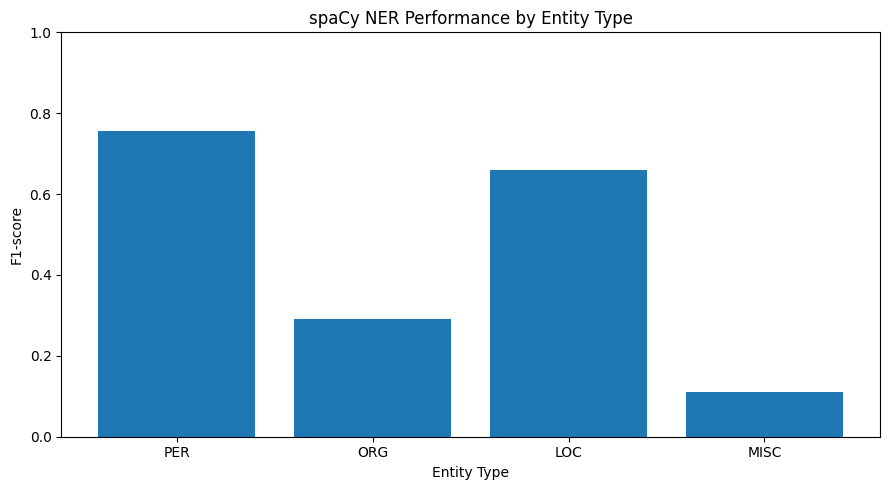

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support

entity_types = ["PER", "ORG", "LOC", "MISC"]

results = []

for entity in entity_types:
    labels = [f"B-{entity}", f"I-{entity}"]

    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels,
        pred_labels,
        labels=labels,
        average="micro",
        zero_division=0
    )

    results.append({
        "Entity Type": entity,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

# Plot the F1-score for each entity type
plt.figure(figsize=(9, 5))
plt.bar(results_df["Entity Type"], results_df["F1-score"])
plt.ylim(0, 1)
plt.xlabel("Entity Type")
plt.ylabel("F1-score")
plt.title("spaCy NER Performance by Entity Type")
plt.tight_layout()
plt.show()

In [21]:
results_df.to_csv(
    "ner_entity_type_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


In [22]:
from collections import Counter
from sklearn.metrics import precision_recall_fscore_support

# Convert CoNLL BIO tags into character-offset entity spans
def get_gold_spans(tokens, tag_ids, label_names):
    spans = []
    text = " ".join(tokens)
    char_positions = []
    position = 0

    for token in tokens:
        start = position
        end = start + len(token)
        char_positions.append((start, end))
        position = end + 1

    current_label = None
    current_start = None
    current_end = None

    for (start, end), tag_id in zip(char_positions, tag_ids):
        tag = label_names[tag_id]

        if tag.startswith("B-"):
            if current_label:
                spans.append((current_start, current_end, current_label))
            current_label = tag[2:]
            current_start, current_end = start, end

        elif tag.startswith("I-") and current_label == tag[2:]:
            current_end = end

        else:
            if current_label:
                spans.append((current_start, current_end, current_label))
            current_label = None
            current_start = current_end = None

    if current_label:
        spans.append((current_start, current_end, current_label))

    return text, spans


label_names = dataset["test"].features["ner_tags"].feature.names
test_subset = dataset["test"].select(range(500))

gold_total = Counter()
pred_total = Counter()
correct_total = Counter()

for example in test_subset:
    text, gold_spans = get_gold_spans(
        example["tokens"],
        example["ner_tags"],
        label_names
    )

    doc = nlp(text)

    # Map spaCy entity labels to CoNLL categories
    label_map = {
        "PERSON": "PER",
        "ORG": "ORG",
        "GPE": "LOC",
        "LOC": "LOC",
        "FAC": "LOC",
        "NORP": "MISC",
        "EVENT": "MISC",
        "WORK_OF_ART": "MISC",
        "PRODUCT": "MISC",
        "LANGUAGE": "MISC"
    }

    gold_set = set(gold_spans)
    pred_set = {
        (ent.start_char, ent.end_char, label_map[ent.label_])
        for ent in doc.ents
        if ent.label_ in label_map
    }

    for span in gold_set:
        gold_total[span[2]] += 1

    for span in pred_set:
        pred_total[span[2]] += 1

    for span in gold_set & pred_set:
        correct_total[span[2]] += 1

for entity_type in ["PER", "ORG", "LOC", "MISC"]:
    gold = gold_total[entity_type]
    predicted = pred_total[entity_type]
    correct = correct_total[entity_type]

    precision = correct / predicted if predicted else 0
    recall = correct / gold if gold else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    print(f"\n{entity_type}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall:    {recall:.3f}")
    print(f"F1-score:  {f1:.3f}")
    print(f"Gold entities: {gold}")
    print(f"Predicted entities: {predicted}")


PER
Precision: 0.833
Recall:    0.597
F1-score:  0.696
Gold entities: 442
Predicted entities: 317

ORG
Precision: 0.312
Recall:    0.255
F1-score:  0.281
Gold entities: 188
Predicted entities: 154

LOC
Precision: 0.758
Recall:    0.719
F1-score:  0.738
Gold entities: 288
Predicted entities: 273

MISC
Precision: 0.397
Recall:    0.385
F1-score:  0.391
Gold entities: 65
Predicted entities: 63


,Entity Type,Precision,Recall,F1-score
0,PER,0.833,0.597,0.696
1,ORG,0.312,0.255,0.281
2,LOC,0.758,0.719,0.738
3,MISC,0.397,0.385,0.391


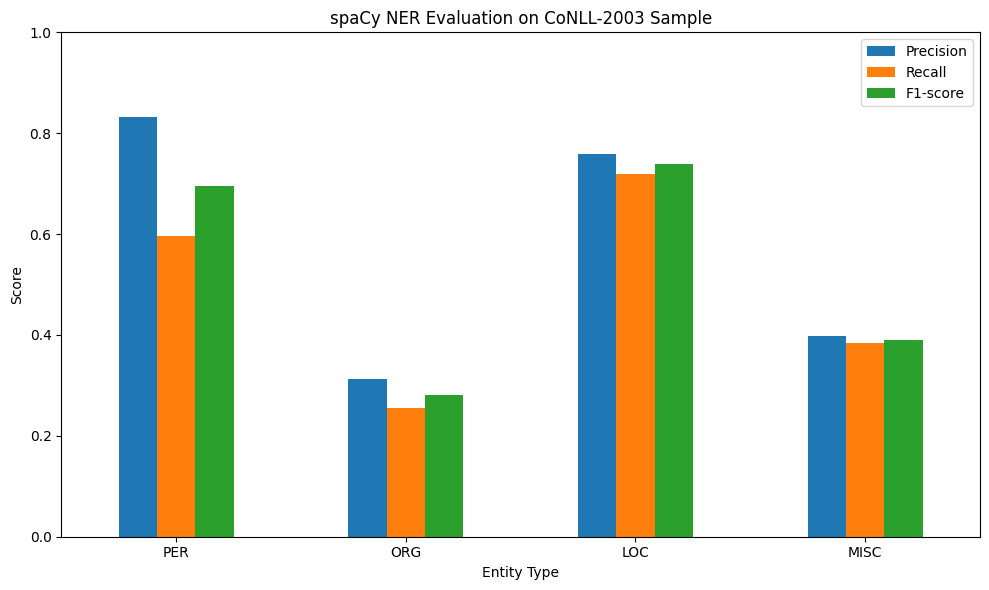

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

results_df = pd.DataFrame({
    "Entity Type": ["PER", "ORG", "LOC", "MISC"],
    "Precision": [0.833, 0.312, 0.758, 0.397],
    "Recall":    [0.597, 0.255, 0.719, 0.385],
    "F1-score":  [0.696, 0.281, 0.738, 0.391]
})

display(results_df.round(3))

# Plot comparison
results_df.plot(
    x="Entity Type",
    y=["Precision", "Recall", "F1-score"],
    kind="bar",
    figsize=(10, 6)
)

plt.title("spaCy NER Evaluation on CoNLL-2003 Sample")
plt.ylabel("Score")
plt.xlabel("Entity Type")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [24]:
results_df.to_csv("ner_evaluation_results.csv", index=False)

print("NER evaluation results saved!")

NER evaluation results saved!


In [27]:
import pandas as pd

comparison_text = """
Microsoft CEO Satya Nadella visited London to meet
officials from the United Kingdom. He later travelled
to Paris to discuss technology with Google executives.
"""

# Run both approaches
rule_doc = rule_nlp(comparison_text)
model_doc = nlp(comparison_text)

def get_entity_table(doc, method):
    rows = []

    for ent in doc.ents:
        rows.append({
            "Method": method,
            "Entity": ent.text,
            "Category": ent.label_
        })

    return rows

comparison_results = (
    get_entity_table(rule_doc, "Rule-based")
    + get_entity_table(model_doc, "spaCy model")
)

comparison_df = pd.DataFrame(comparison_results)
display(comparison_df)

# Visualize model-based results
from spacy import displacy

displacy.render(model_doc, style="ent", jupyter=True)

,Method,Entity,Category
0,Rule-based,Microsoft,ORG
1,Rule-based,Satya Nadella,PERSON
2,Rule-based,London,GPE
3,Rule-based,United Kingdom,GPE
4,Rule-based,Paris,GPE
5,Rule-based,Google,ORG
6,spaCy model,Microsoft,ORG
7,spaCy model,Satya Nadella,PERSON
8,spaCy model,London,GPE
9,spaCy model,the United Kingdom,GPE


## Findings

The pretrained spaCy model and the rule-based system provide
two different approaches to named entity recognition.

The rule-based system identifies entities that match predefined
patterns, making its predictions transparent and easy to control.
However, it may miss unfamiliar entities that are not included
in its rules.

The pretrained spaCy model can recognize a broader range of
entities from context. On the evaluated sample of 500 CoNLL-2003
test examples, location entities achieved the highest F1-score
(0.738), followed by people (0.696), miscellaneous entities
(0.391), and organizations (0.281).

These results are preliminary and apply only to the evaluated
sample. Differences between the CoNLL-2003 annotation scheme
and spaCy's entity categories, as well as tokenization differences,
may affect the evaluation.

Future improvements include evaluating the full test set,
refining label mappings, and comparing additional NER models.